In [1]:
import polars as pl

## Data reading

In [2]:
DATA_DIR = "data"

In [3]:
df_taxi_zones = pl.scan_csv(f"{DATA_DIR}/taxi_zone_lookup.csv")

In [4]:
# I only load 10–12 months of data because my PC has limited RAM, and otherwise the kernel crashes.

dfs = []
for month in range(10, 13):
    df = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet")
    df = df.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    dfs.append(df)
df = pl.concat(dfs)

Include rides only within specific date.

In [5]:
df = df.filter(
    pl.col("tpep_pickup_datetime").dt.year() == 2024,
    pl.col("tpep_dropoff_datetime") <= pl.datetime(2025, 1, 1),
)

In [6]:
df = df.with_columns(
    pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
    pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
)

Optimize data types (integers and one categorical string column).

In [7]:
df = df.with_columns(
    pl.col("passenger_count", "RatecodeID", "payment_type", "VendorID").cast(pl.UInt8),
    pl.col("PULocationID", "DOLocationID").cast(pl.UInt16),
    pl.col("store_and_fwd_flag").cast(pl.Enum(["N", "Y"])),
)

## Data cleaning and filtering

Fill `NULL` values.

In [8]:
df = df.with_columns(pl.col("passenger_count").fill_null(1))

Remove rides with zero passengers.

In [9]:
df = df.filter(pl.col("passenger_count") > 0)

Clip number of passengers.

In [10]:
df = df.with_columns(pl.col("passenger_count").clip(upper_bound=6))

Remove rides lasting over 2 hours.

In [11]:
trip_duration = pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")

df = df.filter(
    trip_duration > pl.duration(seconds=0),
    trip_duration <= pl.duration(hours=2),
)

Replace money related columns with absolute value and remove rides with over 1000 dollars costs.

In [12]:
MONEY_COLS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

In [13]:
df = df.with_columns(pl.col(MONEY_COLS).abs())

In [14]:
df = df.filter(pl.max_horizontal(MONEY_COLS) <= 1000)

Remove rows with values of `RatecodeID` or `VendorID` missing or outside those defined in the data dictionary.

In [15]:
df = df.filter(
    pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99]),
    pl.col("VendorID").is_in([1, 2, 6, 7]),
)

## Data transformation

Combine payment type values.

In [16]:
# Codes 3-6 (no charge, dispute, unknown, voided trip) and 0 (flex fare) are merged into "Other" (3)
df = df.with_columns(pl.col("payment_type").replace({0: 3, 4: 3, 5: 3, 6: 3}))

PAYMENT_TYPES = {
    "Credit card": 1,
    "Cash": 2,
    "Other": 3,
}

Replace `PULocationID` and `DOLocationID` with borough names by joining taxi zone lookup and removing unnecessary columns.

In [17]:
zones = df_taxi_zones.select(
    pl.col("LocationID").cast(pl.UInt16),
    pl.col("Borough"),
)

df = (
    df.join(
        zones.rename(
            {
                "LocationID": "PULocationID",
                "Borough": "PU_Borough",
            }
        ),
        on="PULocationID",
        how="left",
    )
    .join(
        zones.rename(
            {
                "LocationID": "DOLocationID",
                "Borough": "DO_Borough",
            }
        ),
        on="DOLocationID",
        how="left",
    )
    .drop("PULocationID", "DOLocationID")
)

Add boolean variable `is_airport_ride`, true if there is non-zero airport fee.

In [18]:
is_airport_ride = pl.col("Airport_fee").fill_null(0.0) > 0.0

df = df.with_columns(is_airport_ride.alias("is_airport_ride"))

Add boolean variable `is_rush_hour`, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays.

In [19]:
is_weekday = pl.col("tpep_pickup_datetime").dt.weekday() <= 5

is_morning_rush = (
    pl.col("tpep_pickup_datetime")
    .dt.time()
    .is_between(pl.time(6, 30), pl.time(9, 30), closed="left")
)
is_evening_rush = (
    pl.col("tpep_pickup_datetime")
    .dt.time()
    .is_between(pl.time(15, 30), pl.time(20, 0), closed="left")
)

is_rush_hour = is_weekday & (is_morning_rush | is_evening_rush)

df = df.with_columns(is_rush_hour.alias("is_rush_hour"))

## Feature extraction

Apply dummy encoding to features: payment type, pickup borough, dropoff borough.

In [20]:
# This dummy encoding was proposed by AI. The naive `to_dummies` requires materialization.

boroughs = (
    df_taxi_zones.select(pl.col("Borough").drop_nulls().unique().sort())
    .collect()
    .to_series()
    .to_list()
)

df = df.with_columns(
    # payment type dummies
    *[
        (pl.col("payment_type") == code).alias(f"payment_type_{name}")
        for name, code in PAYMENT_TYPES.items()
    ],
    # borough dummies (drop first category to avoid collinearity)
    *[(pl.col("PU_Borough") == b).alias(f"PU_Borough_{b}") for b in boroughs[1:]],
    *[(pl.col("DO_Borough") == b).alias(f"DO_Borough_{b}") for b in boroughs[1:]],
)

In [21]:
# Payment type is not dropped-first: every category is needed for the per-type totals below

# df = df.to_dummies(columns=["payment_type"])
# df = df.to_dummies(columns=["PU_Borough", "DO_Borough"], drop_first=True)

Add integer variables for counting daily events: total number of rides (target variable), number of airport rides, number of rush hour rides.

Add features aggregating daily rides information: average fare amount, median distance, sum of total amounts, total amount paid by card, cash, and other, total congestion surcharge, total number of passengers.

In [22]:
df_daily = (
    df.group_by(pl.col("tpep_pickup_datetime").dt.date().alias("date"))
    .agg(
        pl.len().alias("total_rides"),
        pl.col("is_airport_ride").sum().alias("airport_rides"),
        pl.col("is_rush_hour").sum().alias("rush_hour_rides"),
        pl.col("fare_amount").mean().alias("fare_amount_mean"),
        pl.col("trip_distance").median().alias("trip_distance_median"),
        pl.col("total_amount").sum().alias("total_amount_sum"),
        pl.col("congestion_surcharge").sum().alias("congestion_surcharge_sum"),
        pl.col("passenger_count").sum().alias("passenger_count_sum"),
        # Total amount paid for given payment type
        *[
            (pl.col(f"payment_type_{name}") * pl.col("total_amount"))
            .sum()
            .alias("total_amount_" + name.lower().replace(" ", "_"))
            for name in PAYMENT_TYPES
        ],
        # Daily rides per pickup / dropoff borough (optional)
        # cs.starts_with("PU_Borough_").sum().name.prefix("rides_"),
        # cs.starts_with("DO_Borough_").sum().name.prefix("rides_"),
    )
    .sort("date")
)

Add time features: `quarter`, `month`, `day_of_month`, `day_of_week`, `is_weekend` (boolean).

In [23]:
df_daily = df_daily.with_columns(
    pl.col("date").dt.quarter().alias("quarter"),
    pl.col("date").dt.month().alias("month"),
    pl.col("date").dt.day().alias("day_of_month"),
    pl.col("date").dt.weekday().alias("day_of_week"),
    (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
)

Exclude other columns, unnecessary for machine learning, e.g. IDs, timestamps, unused financial information.

In [24]:
# df_daily already contains required columns, without redundant, additional from raw df, so we skip this part.

# df = df.drop("VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "RatecodeID", "store_and_fwd_flag", "mta_tax", "tip_amount", "tolls_amount", "improvement_surcharge", "Airport_fee", "extra")

Save results as `dataset.parquet` file.

In [25]:
df_daily = df_daily.collect()
df_daily.write_parquet("./data/dataset.parquet")

## Data anylysis

In [26]:
dataset = pl.read_parquet("./data/dataset.parquet")

In [27]:
dataset.shape

(93, 17)

In [28]:
dataset.schema

Schema([('date', Date),
        ('total_rides', UInt32),
        ('airport_rides', UInt32),
        ('rush_hour_rides', UInt32),
        ('fare_amount_mean', Float64),
        ('trip_distance_median', Float64),
        ('total_amount_sum', Float64),
        ('congestion_surcharge_sum', Float64),
        ('passenger_count_sum', Int64),
        ('total_amount_credit_card', Float64),
        ('total_amount_cash', Float64),
        ('total_amount_other', Float64),
        ('quarter', Int8),
        ('month', Int8),
        ('day_of_month', Int8),
        ('day_of_week', Int8),
        ('is_weekend', Boolean)])

In [29]:
display(dataset.head())
display(dataset.describe())

date,total_rides,airport_rides,rush_hour_rides,fare_amount_mean,trip_distance_median,total_amount_sum,congestion_surcharge_sum,passenger_count_sum,total_amount_credit_card,total_amount_cash,total_amount_other,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,i64,f64,f64,f64,i8,i8,i8,i8,bool
2024-09-30,12,3,0,32.558333,4.39,507.7,25.0,21,468.6,39.1,0.0,3,9,30,1,false
2024-10-01,108146,9073,46380,19.712692,1.66,3.1407e6,249332.5,134022,2.6875e6,364936.79,88190.23,4,10,1,2,false
2024-10-02,105370,8524,44736,19.928892,1.66,3.0852e6,243705.0,133528,2.6310e6,369204.54,84994.99,4,10,2,3,false
2024-10-03,100759,8979,39599,19.231774,1.67,2.8862e6,236057.5,133098,2.4352e6,364317.04,86675.36,4,10,3,4,false
2024-10-04,101961,9050,38849,19.606642,1.69,2.9596e6,238032.5,138983,2.4799e6,388344.66,91325.39,4,10,4,5,false


statistic,date,total_rides,airport_rides,rush_hour_rides,fare_amount_mean,trip_distance_median,total_amount_sum,congestion_surcharge_sum,passenger_count_sum,total_amount_credit_card,total_amount_cash,total_amount_other,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""93""",93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-11-15 00:00:00""",106941.27957,9099.075269,31509.182796,20.404746,1.715054,3.1526e6,247076.623656,143857.569892,2.6802e6,376775.190538,95690.512151,3.989247,10.978495,15.989247,3.946237,0.27957
"""std""",null,21313.115968,2384.2064,21406.609722,1.642309,0.295295,642450.165908,51176.568689,26485.613261,598173.857922,51287.151335,15350.22425,0.103695,0.846714,8.975201,2.023587,null
"""min""","""2024-09-30""",12.0,3.0,0.0,17.583512,1.5,507.7,25.0,21.0,468.6,39.1,0.0,3.0,9.0,1.0,1.0,0.0
"""25%""","""2024-10-23""",95805.0,7666.0,0.0,19.606642,1.62,2.8862e6,219495.0,133098.0,2.4418e6,364317.04,88862.27,4.0,10.0,8.0,2.0,null
"""50%""","""2024-11-15""",110200.0,9473.0,42262.0,20.236492,1.68,3.2387e6,254151.0,144955.0,2.7564e6,384794.32,96450.67,4.0,11.0,16.0,4.0,null
"""75%""","""2024-12-08""",120680.0,10761.0,48816.0,20.987901,1.73,3.5445e6,282190.0,159708.0,3.0522e6,402828.14,103748.21,4.0,12.0,24.0,6.0,null
"""max""","""2024-12-31""",141658.0,14900.0,56559.0,32.558333,4.39,4.4614e6,330435.0,199410.0,3.9161e6,442157.35,123894.72,4.0,12.0,31.0,7.0,1.0


In [30]:
dataset_pd = dataset.sort("date").to_pandas()

<Axes: title={'center': 'Distribution of daily rides'}, xlabel='Daily number of rides', ylabel='Number of days'>

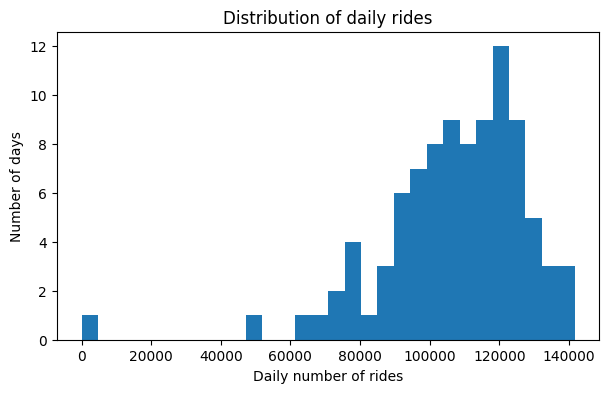

In [31]:
dataset_pd["total_rides"].plot(
    kind="hist",
    bins=30,
    figsize=(7, 4),
    xlabel="Daily number of rides",
    ylabel="Number of days",
    title="Distribution of daily rides",
)

<Axes: title={'center': 'Daily number of rides'}, xlabel='Date', ylabel='Number of rides'>

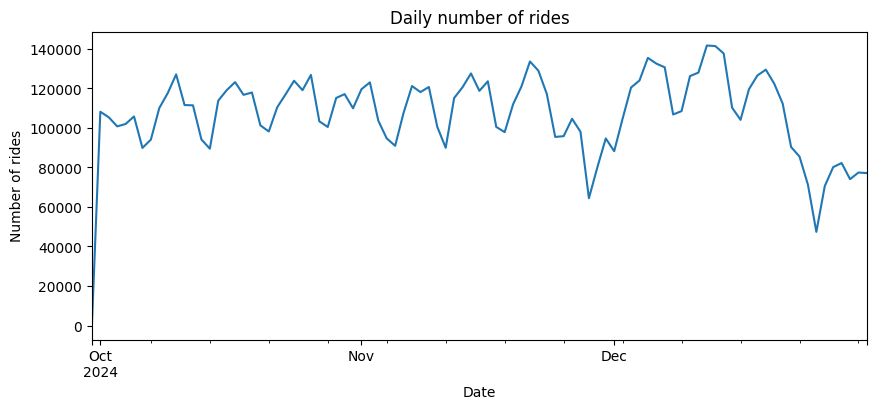

In [32]:
dataset_pd.plot(
    x="date",
    y="total_rides",
    kind="line",
    figsize=(10, 4),
    legend=False,
    xlabel="Date",
    ylabel="Number of rides",
    title="Daily number of rides",
)